<a href="https://colab.research.google.com/github/sankalpgp/T170800517_TSNIF_AIML/blob/sankalpgp%2Fv/TNS_Day_8_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 🎯 Objective
In this step, we will:
- Setup Kaggle API
- Download dataset from Kaggle
- Load dataset into Pandas DataFrame

In [ ]:
from google.colab import files

uploaded = files.upload()  # Select kaggle.json from your computer

Saving kaggle.json to kaggle.json


## ⚙️ Configure Kaggle API

In [ ]:
import os
import shutil

# Create Kaggle directory
os.makedirs('/root/.kaggle', exist_ok=True)

# Move uploaded file
shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')

# Set permissions
os.chmod('/root/.kaggle/kaggle.json', 600)

## 📥 Download Dataset from Kaggle

Dataset: Simple Rainfall Classification Dataset

In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle datasets download -d sujithmandala/simple-rainfall-classification-dataset

Dataset URL: https://www.kaggle.com/datasets/sujithmandala/simple-rainfall-classification-dataset
License(s): CC-BY-SA-4.0
100% 804/804 [00:00<00:00, 2.31MB/s]



## 📦 Extract Dataset

In [ ]:
import zipfile

with zipfile.ZipFile('simple-rainfall-classification-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('rainfall_dataset')

## 📊 Load Dataset into Pandas

In [ ]:
import os

print(os.listdir('rainfall_dataset'))

['rainfall.csv']


In [ ]:
import pandas as pd

# Replace filename with the actual CSV name printed above
df = pd.read_csv('rainfall_dataset/rainfall.csv')

print(df.head())
print(df.shape)

         date  rainfall  temperature  humidity  wind_speed weather_condition
0  2022-01-01      12.5         15.2      78.0         8.5             Rainy
1  2022-01-02       8.2         17.8      65.0         5.2             Rainy
2  2022-01-03       0.0         20.1      52.0         3.1             Sunny
3  2022-01-04       3.7         18.6      71.0         6.7             Rainy
4  2022-01-05      21.1         14.8      82.0         9.3             Rainy
(54, 6)


## 🔍 Basic Structure Check

In [ ]:
# Shape of dataset
df.shape

# Column names
df.columns

Index(['date', 'rainfall', 'temperature', 'humidity', 'wind_speed',
       'weather_condition'],
      dtype='object')

## 🎯 Objective
In this step, we will:
- Understand dataset structure
- Check data types
- Identify missing values
- Generate statistical summary

## 🔍 View Dataset
Display first and last few records

In [ ]:
# First 5 rows
df.head()

,date,rainfall,temperature,humidity,wind_speed,weather_condition
0,2022-01-01,12.5,15.2,78.0,8.5,Rainy
1,2022-01-02,8.2,17.8,65.0,5.2,Rainy
2,2022-01-03,0.0,20.1,52.0,3.1,Sunny
3,2022-01-04,3.7,18.6,71.0,6.7,Rainy
4,2022-01-05,21.1,14.8,82.0,9.3,Rainy


In [ ]:
# Last 5 rows
df.tail()

,date,rainfall,temperature,humidity,wind_speed,weather_condition
49,2022-02-19,17.3,15.9,83.0,8.6,Rainy
50,2022-02-20,9.6,18.6,71.0,6.7,Rainy
51,2022-02-21,0.0,21.3,55.0,5.1,Sunny
52,2022-02-22,7.4,16.8,77.0,8.9,Rainy
53,Co,NaN,NaN,NaN,NaN,NaN


## 📐 Dataset Shape
Check number of rows and columns

In [ ]:
print("Rows and Columns:", df.shape)

Rows and Columns: (54, 6)


## 🏷 Column Names
List all available features

In [ ]:
print("Columns in dataset:")
print(df.columns)

Columns in dataset:
Index(['date', 'rainfall', 'temperature', 'humidity', 'wind_speed',
       'weather_condition'],
      dtype='object')


## 🔢 Data Types
Understand numeric and categorical columns

In [ ]:
df.dtypes

,0
date,object
rainfall,float64
temperature,float64
humidity,float64
wind_speed,float64
weather_condition,object


## ℹ Dataset Information
Summary of memory usage and non-null values

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               54 non-null     object 
 1   rainfall           53 non-null     float64
 2   temperature        53 non-null     float64
 3   humidity           53 non-null     float64
 4   wind_speed         53 non-null     float64
 5   weather_condition  53 non-null     object 
dtypes: float64(4), object(2)
memory usage: 2.7+ KB


## ❓ Missing Values Check
Find null values in each column

In [ ]:
df.isnull().sum()

,0
date,0
rainfall,1
temperature,1
humidity,1
wind_speed,1
weather_condition,1


## 📊 Statistical Summary
Numerical overview of dataset

In [ ]:
df.describe()

,rainfall,temperature,humidity,wind_speed
count,53.000000,53.000000,53.000000,53.000000
mean,9.049057,17.950943,69.245283,6.403774
std,6.712521,2.500663,11.969361,2.209069
min,0.000000,13.900000,44.000000,2.100000
25%,3.900000,16.100000,62.000000,4.700000
50%,8.300000,17.800000,72.000000,6.700000
75%,14.800000,19.400000,78.000000,8.300000
max,21.800000,23.400000,89.000000,10.500000


## 🧠 Initial Observations
While exploring, observe:
- Which columns are numerical
- Which columns are categorical
- Any missing values
- Minimum and maximum values
- Possible outliers

## ✅ Outcome

After this step, we understand:
- Dataset structure
- Data quality
- Feature types
- Summary statistics

#Correlation Analysis

## 🎯 Objective
In this step, we will:
- Understand relationships between numerical features
- Identify strong positive/negative correlations
- Detect multicollinearity

## 📌 What is Correlation?

Correlation measures how strongly two variables are related.

- +1 → Strong positive relationship
- -1 → Strong negative relationship
- 0 → No relationship

## 🔢 Compute Correlation Matrix

In [ ]:
# Compute correlation matrix (only numeric columns)
corr_matrix = df.corr(numeric_only=True)

corr_matrix

,rainfall,temperature,humidity,wind_speed
rainfall,1.000000,-0.790566,0.821357,0.733376
temperature,-0.790566,1.000000,-0.966097,-0.902996
humidity,0.821357,-0.966097,1.000000,0.951643
wind_speed,0.733376,-0.902996,0.951643,1.000000


## 🎨 Visualize Correlation using Heatmap

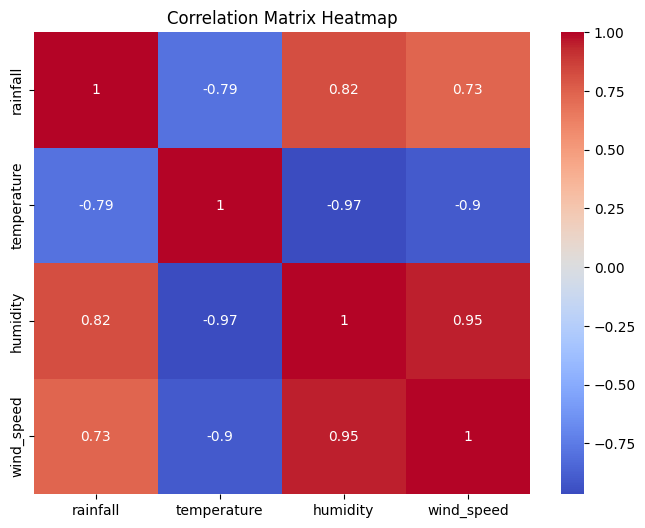

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix Heatmap")
plt.show()

## 🔍 Focus on Target Variable

Check how features relate to the target (e.g., rainfall)

In [ ]:
# Replace 'rainfall' with your target column if different
corr_matrix["rainfall"].sort_values(ascending=False)

,rainfall
rainfall,1.000000
humidity,0.821357
wind_speed,0.733376
temperature,-0.790566


## ⚠️ Detect Multicollinearity

Highly correlated features can affect model performance

In [ ]:
# Find highly correlated feature pairs (> 0.8)
high_corr = []

for i in corr_matrix.columns:
    for j in corr_matrix.columns:
        if i != j and abs(corr_matrix[i][j]) > 0.8:
            high_corr.append((i, j, corr_matrix[i][j]))

high_corr

[('rainfall', 'humidity', np.float64(0.8213569723603099)),
 ('temperature', 'humidity', np.float64(-0.9660971268282758)),
 ('temperature', 'wind_speed', np.float64(-0.9029958088261343)),
 ('humidity', 'rainfall', np.float64(0.8213569723603099)),
 ('humidity', 'temperature', np.float64(-0.9660971268282758)),
 ('humidity', 'wind_speed', np.float64(0.9516425912012718)),
 ('wind_speed', 'temperature', np.float64(-0.9029958088261343)),
 ('wind_speed', 'humidity', np.float64(0.9516425912012718))]

## 🧠 Observations to Make

- Which features strongly affect rainfall?
- Are there strong positive or negative correlations?
- Any redundant features (multicollinearity)?

#Distribution Analysis

## 🎯 Objective
In this step, we will:
- Understand how data is distributed
- Identify skewness (left/right)
- Detect outliers
- Analyze spread of data

## 📌 What is Distribution?

Distribution shows how values of a variable are spread.

We analyze:
- Shape (Normal / Skewed)
- Spread (Variance)
- Outliers

## 📊 Histogram (Distribution of Features)

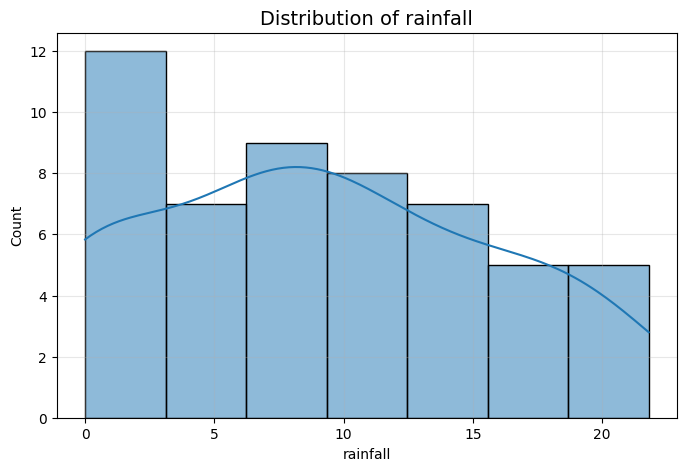

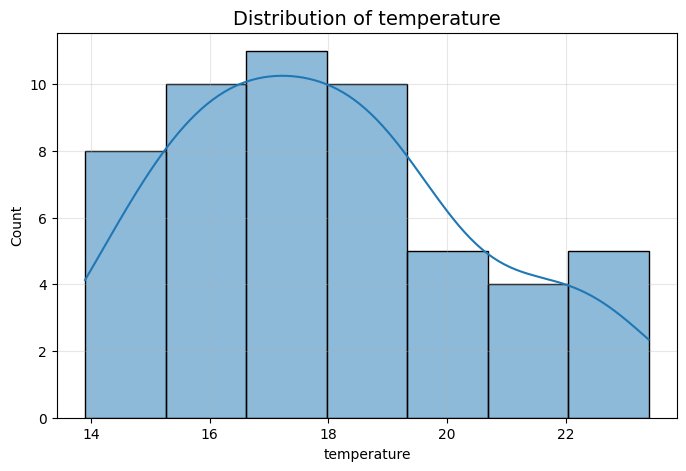

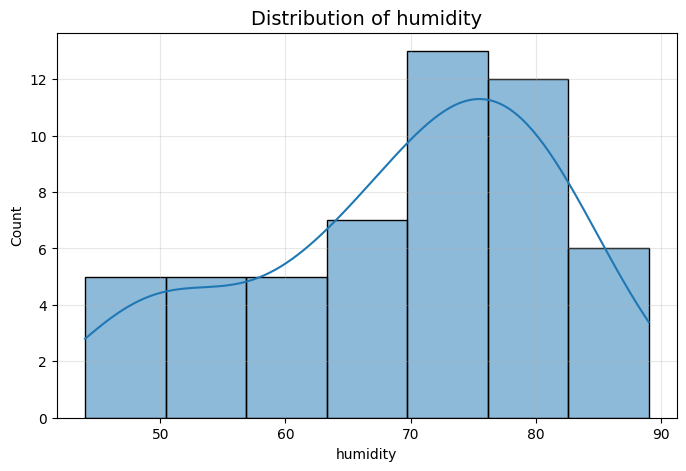

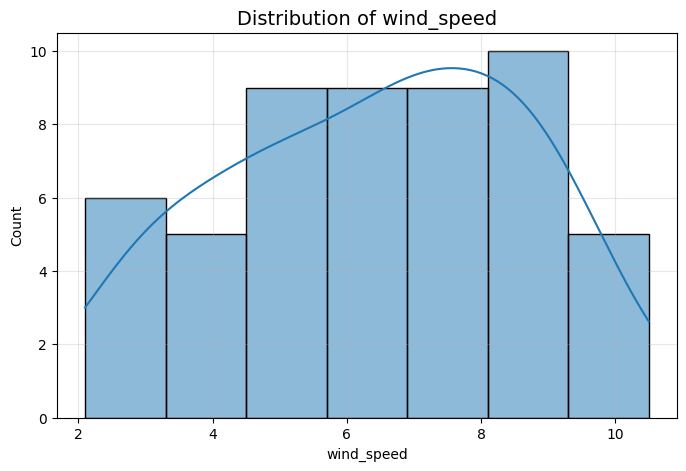

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure(figsize=(8,5))

    sns.histplot(
        data=df,
        x=col,
        kde=True
    )

    plt.title(f'Distribution of {col}', fontsize=14)
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.grid(True, alpha=0.3)

    plt.show()

## 🔍 Observations from Histogram

- Is data symmetric?
- Is it skewed (left/right)?
- Are values concentrated or spread out?

## 📦 Boxplot (Outlier Detection)

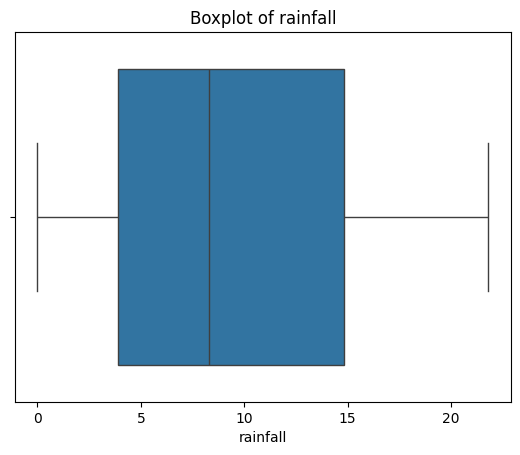

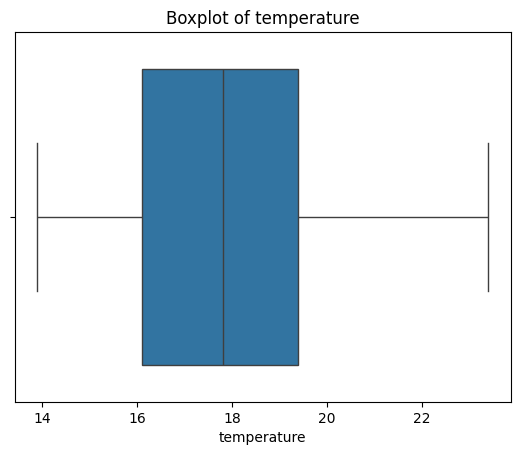

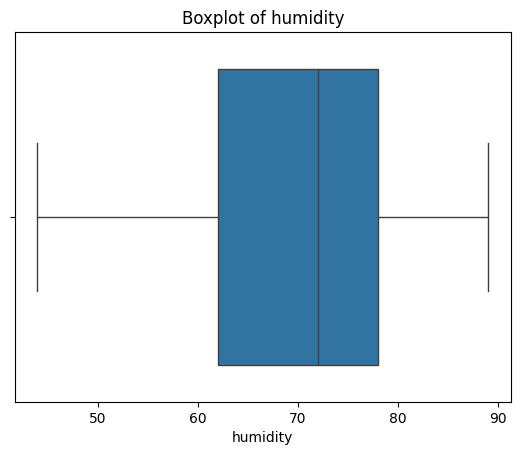

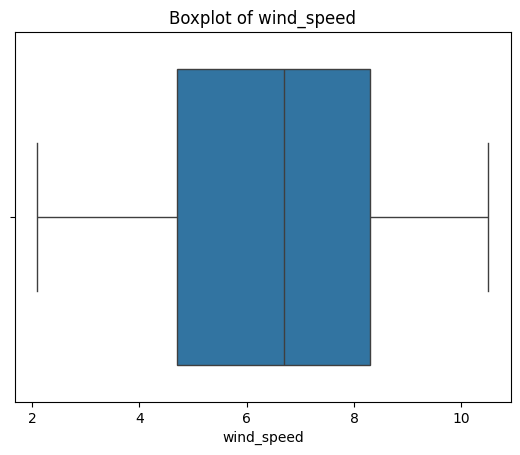

In [ ]:
import seaborn as sns

# Boxplot for each numeric column
for col in df.select_dtypes(include='number').columns:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

## ⚠️ Observations from Boxplot

- Points outside whiskers = Outliers
- Helps detect extreme values

## 📈 KDE Plot (Smooth Distribution Curve)

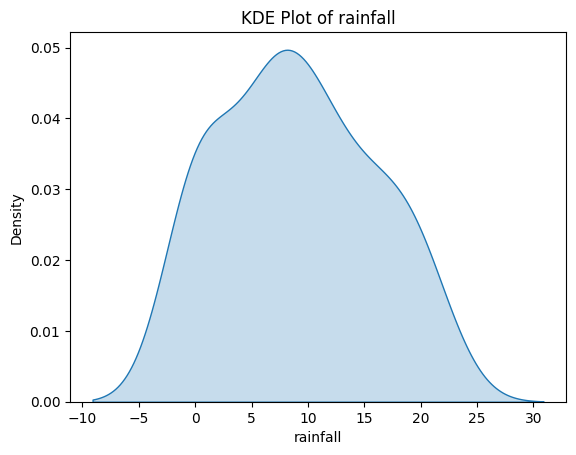

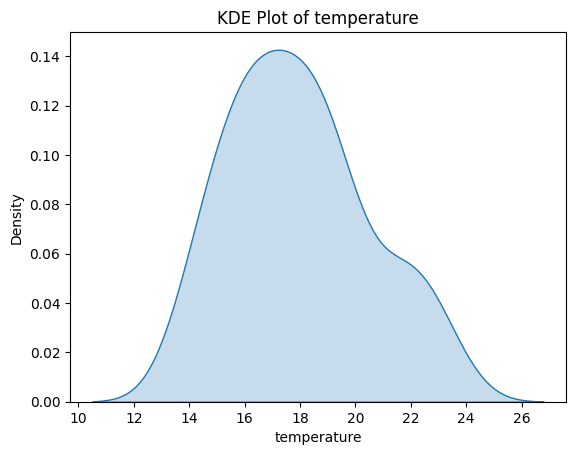

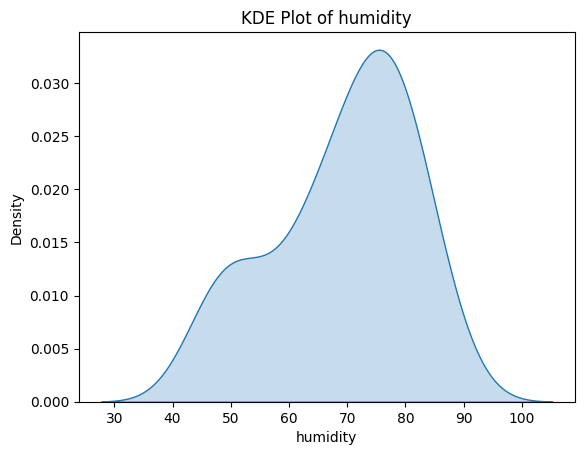

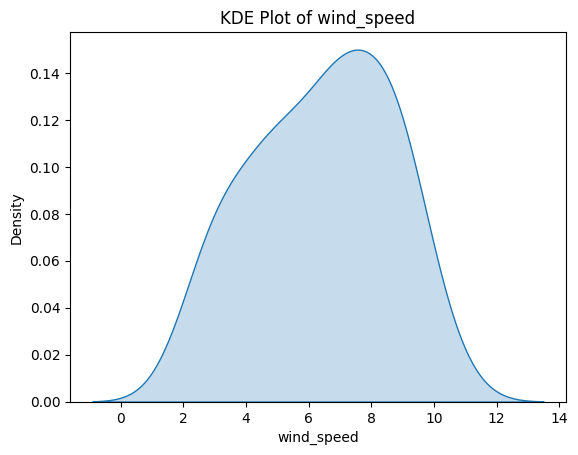

In [ ]:
for col in df.select_dtypes(include='number').columns:
    plt.figure()
    sns.kdeplot(df[col], fill=True)
    plt.title(f"KDE Plot of {col}")
    plt.show()

## 🔢 Skewness Calculation

In [ ]:
# Calculate skewness
df.skew(numeric_only=True)

,0
rainfall,0.191925
temperature,0.436075
humidity,-0.564768
wind_speed,-0.207329


## 📌 Interpretation of Skewness

- Skew = 0 → Normal distribution
- Skew > 0 → Right skewed
- Skew < 0 → Left skewed

## 🧠 Observations to Make

- Which features are skewed?
- Are there outliers present?
- Which features are normally distributed?
- Any imbalance in values?

#Insights Extraction & Conclusion

## 🎯 Objective
In this step, we will:
- Derive meaningful insights from EDA
- Summarize key findings
- Understand feature impact on target

## 📌 What are Insights?

Insights are meaningful conclusions derived from data analysis.

They answer:
- What is happening?
- Why is it happening?
- What can we do next?

## 🔍 Basic Aggregations

In [ ]:
# Example statistics
print("Average Rainfall:", df["rainfall"].mean())
print("Maximum Rainfall:", df["rainfall"].max())
print("Minimum Rainfall:", df["rainfall"].min())

Average Rainfall: 9.049056603773584
Maximum Rainfall: 21.8
Minimum Rainfall: 0.0


## 📊 Group-wise Analysis
Analyze how features affect the target

In [ ]:
# Average rainfall by weather condition
if "weather_condition" in df.columns and "rainfall" in df.columns:

    avg_rainfall = df.groupby("weather_condition")["rainfall"].mean()

    print("Average Rainfall by Weather Condition:")
    print(avg_rainfall)

else:
    print("Required columns not found in the dataset.")

Average Rainfall by Weather Condition:
weather_condition
Rainy    11.419048
Sunny     0.000000
Name: rainfall, dtype: float64


## 📈 Feature vs Target Insights

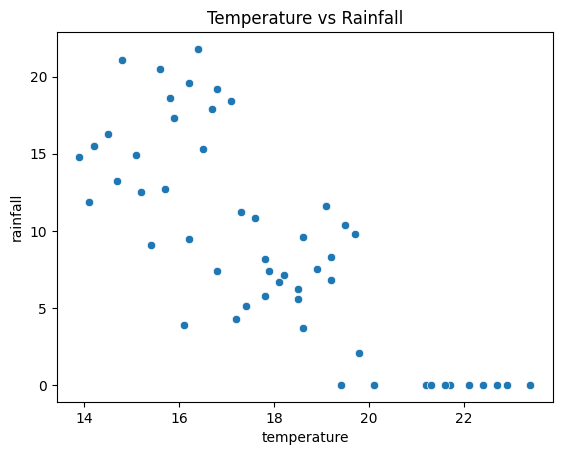

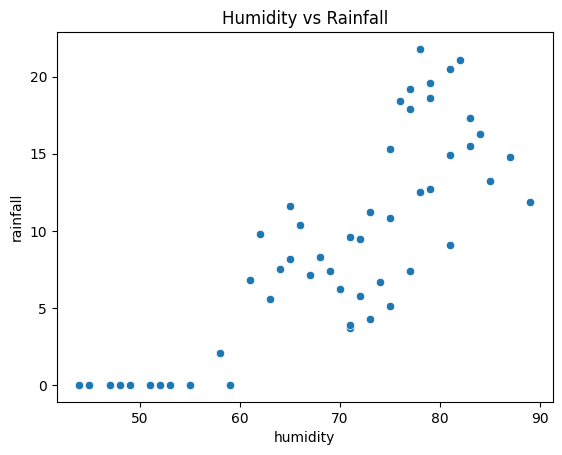

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Example relationship plots
sns.scatterplot(x="temperature", y="rainfall", data=df)
plt.title("Temperature vs Rainfall")
plt.show()

sns.scatterplot(x="humidity", y="rainfall", data=df)
plt.title("Humidity vs Rainfall")
plt.show()

## 🧠 Writing Insights (Important)

Based on previous steps, write insights like:

1. Features strongly correlated with rainfall
2. Distribution patterns (skewness, outliers)
3. Important predictors
4. Any anomalies or unusual patterns

## 📝 Example Insights

- Humidity shows strong positive correlation with rainfall  
- Temperature has weak or negative correlation  
- Some features contain outliers (seen in boxplots)  
- Certain variables are right-skewed  
- Dataset may have imbalance in target classes  

#Level 1: Basic (Understanding Data)

### Q1.
Write code to display the first 10 rows of the dataset.

### Q2.
Find the number of rows and columns in the dataset.

### Q3.
Print all column names.

### Q4.
Write code to check data types of each column.

### Q5.
Find total missing values in each column.

### Q6.
Calculate mean, median, and standard deviation of rainfall.

### Q7.
Find the maximum and minimum value of temperature.

### Q8.
Select only numerical columns from the dataset.

In [ ]:
import pandas as pd
import numpy as np

print("--- Q1: First 10 Rows ---")
display(df.head(10))

print("\n--- Q2: Shape of Dataset ---")
rows, cols = df.shape
print(f"Rows: {rows}, Columns: {cols}")

print("\n--- Q3: Column Names ---")
print(df.columns.tolist())

print("\n--- Q4: Data Types ---")
print(df.dtypes)

print("\n--- Q5: Missing Values ---")
print(df.isnull().sum())

print("\n--- Q6: Purchase_Amount Statistics ---")
print("Mean:", df["Purchase_Amount"].mean())
print("Median:", df["Purchase_Amount"].median())
print("Std Dev:", df["Purchase_Amount"].std())

print("\n--- Q7: Age Min/Max ---")
print("Min Age:", df["Age"].min())
print("Max Age:", df["Age"].max())

print("\n--- Q8: Numerical Columns ---")
numeric_df = df.select_dtypes(include=np.number)
display(numeric_df.head())

--- Q1: First 10 Rows ---


,ID,Age,Salary,Gender,City,Date,Purchase_Amount,Experience,Rating
0,1,22,28000,Male,NaN,2026-01-05,1250,1,4.2
1,2,25,35000,Female,NaN,2026-01-12,2100,2,NaN
2,3,29,48000,Male,Bangalore,2026-01-20,3500,5,4.1
3,4,31,55000,Female,Delhi,2026-02-02,4200,7,4.7
4,5,27,42000,Male,Hyderabad,2026-02-10,2750,4,3.9
5,6,35,72000,Female,Pune,2026-02-18,5800,10,NaN
6,7,24,31000,NaN,Nashik,2026-02-25,1800,2,NaN
7,8,38,85000,Female,Mumbai,2026-03-03,7200,13,4.6
8,9,42,95000,NaN,Bangalore,2026-03-11,9100,17,4.4
9,10,30,52000,Female,Chennai,2026-03-19,3900,6,4.0



--- Q2: Shape of Dataset ---
Rows: 20, Columns: 9

--- Q3: Column Names ---
['ID', 'Age', 'Salary', 'Gender', 'City', 'Date', 'Purchase_Amount', 'Experience', 'Rating']

--- Q4: Data Types ---
ID                   int64
Age                  int64
Salary               int64
Gender              object
City                object
Date                object
Purchase_Amount      int64
Experience           int64
Rating             float64
dtype: object

--- Q5: Missing Values ---
ID                 0
Age                0
Salary             0
Gender             2
City               2
Date               0
Purchase_Amount    0
Experience         0
Rating             5
dtype: int64

--- Q6: Purchase_Amount Statistics ---
Mean: 5177.5
Median: 4050.0
Std Dev: 3699.981329967121

--- Q7: Age Min/Max ---
Min Age: 22
Max Age: 48

--- Q8: Numerical Columns ---


,ID,Age,Salary,Purchase_Amount,Experience,Rating
0,1,22,28000,1250,1,4.2
1,2,25,35000,2100,2,NaN
2,3,29,48000,3500,5,4.1
3,4,31,55000,4200,7,4.7
4,5,27,42000,2750,4,3.9


#Level 2: Correlation Coding

### Q9.
Compute the correlation matrix of the dataset.

### Q10.
Plot a heatmap of the correlation matrix.

### Q11.
Find correlation of all features with rainfall and sort them.

### Q12.
Write code to identify feature pairs with correlation > 0.7.

### Q13.
Extract only highly correlated features into a list.

### Q14.
Drop one feature from each highly correlated pair.

### Q15.
Plot a scatter plot between rainfall and humidity.

--- Q9: Correlation Matrix ---


,ID,Age,Salary,Purchase_Amount,Experience,Rating
ID,1.000000,0.383947,0.402644,0.403043,0.392772,0.163405
Age,0.383947,1.000000,0.997348,0.978114,0.996057,0.520566
Salary,0.402644,0.997348,1.000000,0.983742,0.996692,0.534011
Purchase_Amount,0.403043,0.978114,0.983742,1.000000,0.988771,0.535577
Experience,0.392772,0.996057,0.996692,0.988771,1.000000,0.540476
Rating,0.163405,0.520566,0.534011,0.535577,0.540476,1.000000


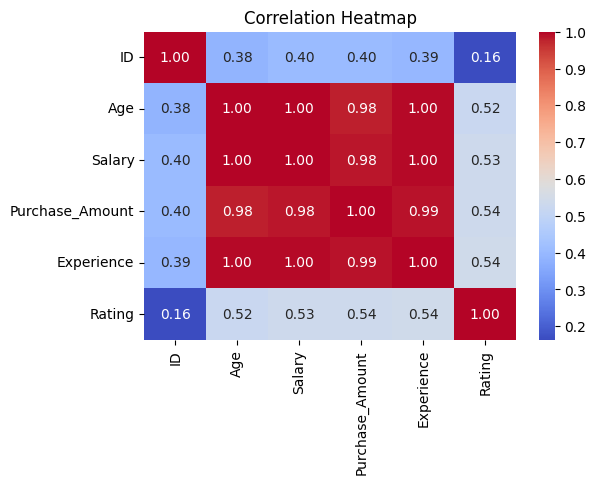


--- Q11: Correlation with Purchase_Amount ---
Purchase_Amount    1.000000
Experience         0.988771
Salary             0.983742
Age                0.978114
Rating             0.535577
ID                 0.403043
Name: Purchase_Amount, dtype: float64

--- Q12 & Q13: Highly Correlated Pairs (> 0.7) ---
Pairs: [('Age', 'Salary', np.float64(0.9973479189801627)), ('Age', 'Purchase_Amount', np.float64(0.9781136645635202)), ('Age', 'Experience', np.float64(0.9960570561561711)), ('Salary', 'Purchase_Amount', np.float64(0.9837422629895227)), ('Salary', 'Experience', np.float64(0.9966923493162312)), ('Purchase_Amount', 'Experience', np.float64(0.9887712114660655))]
Highly Correlated Features: ['Experience', 'Salary', 'Age', 'Purchase_Amount']

--- Q14: Dropped 'Salary' to handle multicollinearity ---
Remaining Columns: ['ID', 'Age', 'Gender', 'City', 'Date', 'Purchase_Amount', 'Experience', 'Rating']


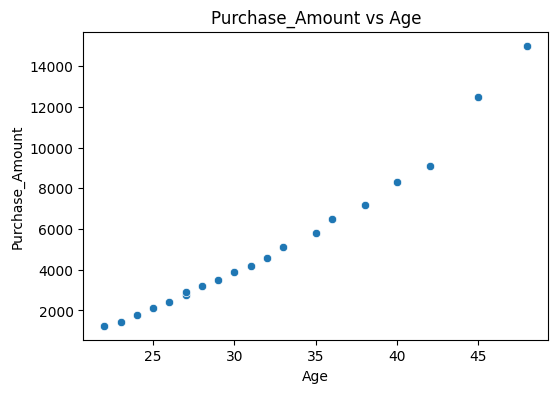

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = df.corr(numeric_only=True)
print("--- Q9: Correlation Matrix ---")
display(corr_matrix)

plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
title = plt.title("Correlation Heatmap")
plt.show()

print("\n--- Q11: Correlation with Purchase_Amount ---")
print(corr_matrix["Purchase_Amount"].sort_values(ascending=False))

print("\n--- Q12 & Q13: Highly Correlated Pairs (> 0.7) ---")
high_corr_pairs = []
high_corr_features = set()
columns = corr_matrix.columns
for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        col1, col2 = columns[i], columns[j]
        if abs(corr_matrix.loc[col1, col2]) > 0.7:
            high_corr_pairs.append((col1, col2, corr_matrix.loc[col1, col2]))
            high_corr_features.add(col1)
            high_corr_features.add(col2)
print("Pairs:", high_corr_pairs)
print("Highly Correlated Features:", list(high_corr_features))

df_reduced = df.drop(columns=["Salary"], errors="ignore")
print("\n--- Q14: Dropped 'Salary' to handle multicollinearity ---")
print("Remaining Columns:", df_reduced.columns.tolist())

plt.figure(figsize=(6, 4))
sns.scatterplot(x="Age", y="Purchase_Amount", data=df)
plt.title("Purchase_Amount vs Age")
plt.show()

#Level 3: Distribution Coding

### Q16.
Plot histograms for all numerical features.

### Q17.
Plot histogram for rainfall with 30 bins.

### Q18.
Create boxplots for all numerical columns.

### Q19.
Identify outliers using boxplot logic (IQR method).

### Q20.
Calculate skewness for all numerical features.

### Q21.
Plot KDE plot for temperature.

### Q22.
Compare mean and median of rainfall using code.

### Q23.
Count how many features are right-skewed.

--- Q16: Histograms for All Numerical Columns ---


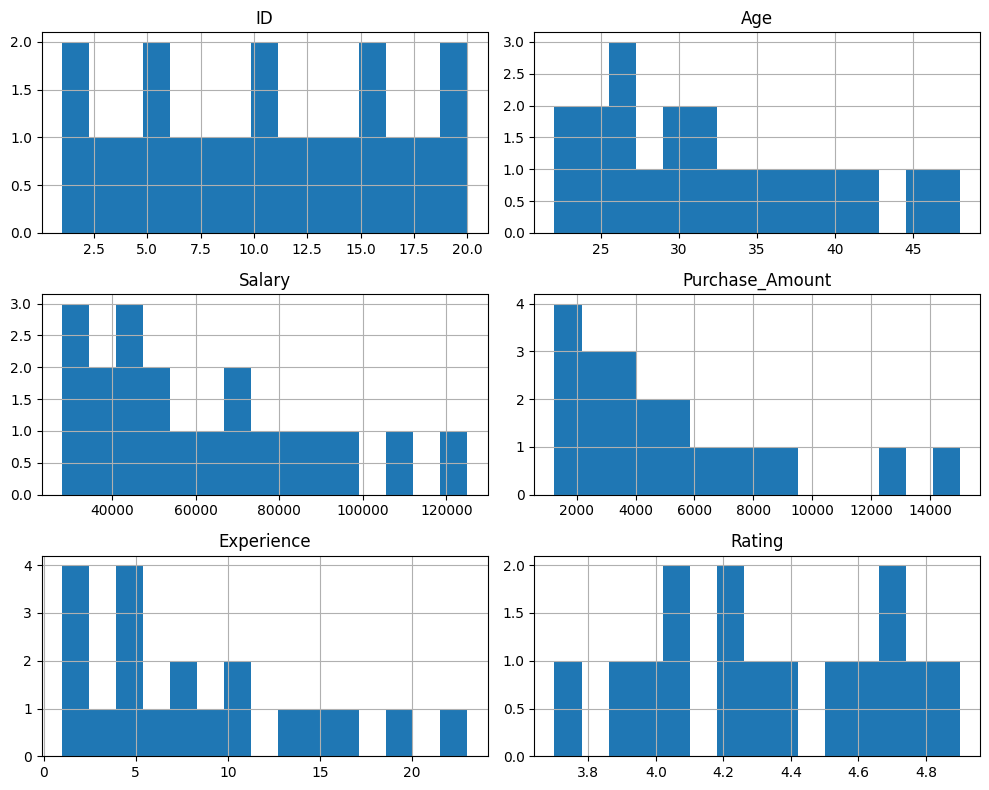

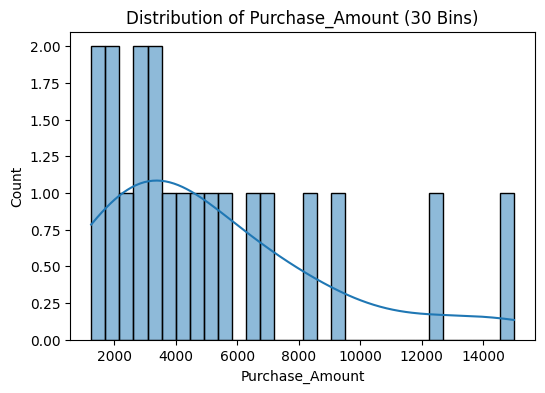


--- Q18: Boxplots ---


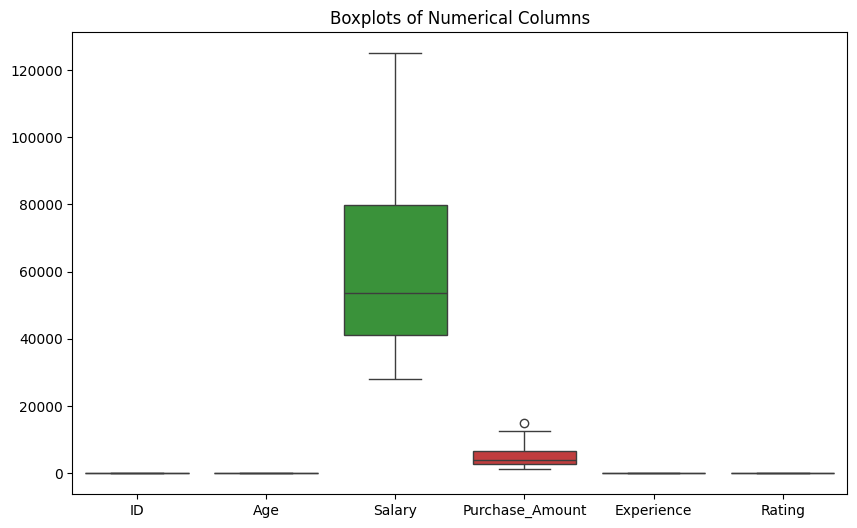


--- Q19: Outliers Detection via IQR ---
ID has 0 outliers: []
Age has 0 outliers: []
Salary has 0 outliers: []
Purchase_Amount has 1 outliers: [15000]
Experience has 0 outliers: []
Rating has 0 outliers: []

--- Q20: Skewness ---
ID                 0.000000
Age                0.673258
Salary             0.783030
Purchase_Amount    1.383910
Experience         0.921405
Rating            -0.058777
dtype: float64


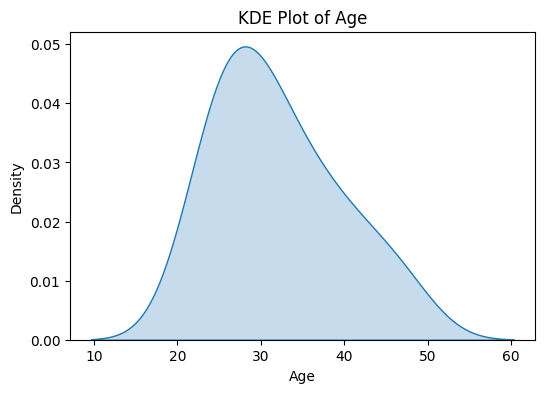


--- Q22: Mean vs Median of Purchase_Amount ---
Mean: 5177.50, Median: 4050.00

--- Q23: Right-Skewed Features (Skew > 0.5) ---
Count: 4
Features: ['Age', 'Salary', 'Purchase_Amount', 'Experience']


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Q16: Histograms for All Numerical Columns ---")
df.hist(bins=15, figsize=(10, 8))
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(df["Purchase_Amount"], bins=30, kde=True)
plt.title("Distribution of Purchase_Amount (30 Bins)")
plt.show()

print("\n--- Q18: Boxplots ---")
plt.figure(figsize=(10, 6))
sns.boxplot(data=df.select_dtypes(include='number'))
plt.title("Boxplots of Numerical Columns")
plt.show()

print("\n--- Q19: Outliers Detection via IQR ---")
for col in df.select_dtypes(include='number').columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
    print(f"{col} has {len(outliers)} outliers: {outliers.tolist()}")

print("\n--- Q20: Skewness ---")
print(df.skew(numeric_only=True))

plt.figure(figsize=(6, 4))
sns.kdeplot(df["Age"].dropna(), fill=True)
plt.title("KDE Plot of Age")
plt.show()

mean_purchase = df["Purchase_Amount"].mean()
median_purchase = df["Purchase_Amount"].median()
print(f"\n--- Q22: Mean vs Median of Purchase_Amount ---\nMean: {mean_purchase:.2f}, Median: {median_purchase:.2f}")

skew_vals = df.skew(numeric_only=True)
right_skewed = skew_vals[skew_vals > 0.5]
print(f"\n--- Q23: Right-Skewed Features (Skew > 0.5) ---\nCount: {len(right_skewed)}\nFeatures: {right_skewed.index.tolist()}")

#Level 4: Insights Coding

### Q24.
Find average rainfall grouped by weather condition.

### Q25.
Find top 3 days/records with highest rainfall.

### Q26.
Find rows where rainfall is greater than average.

### Q27.
Compare average temperature when rainfall is high vs low.

### Q28.
Create a new column "high_rainfall" (1 if rainfall > mean else 0).

### Q29.
Count how many records fall into high rainfall category.

### Q30.
Find correlation only for high rainfall data.

In [ ]:
print("--- Q24: Average Purchase_Amount by Gender ---")
if "Gender" in df.columns:
    print(df.groupby("Gender")["Purchase_Amount"].mean())

print("\n--- Q25: Top 3 Highest Purchase_Amount Records ---")
display(df.nlargest(3, "Purchase_Amount"))

print("\n--- Q26: Rows with Purchase_Amount > Average ---")
mean_purchase = df["Purchase_Amount"].mean()
display(df[df["Purchase_Amount"] > mean_purchase].head())

print("\n--- Q27: Avg Age when Purchase_Amount is high vs low ---")
high_purchase_age = df[df["Purchase_Amount"] > mean_purchase]["Age"].mean()
low_purchase_age = df[df["Purchase_Amount"] <= mean_purchase]["Age"].mean()
print(f"Avg Age when Purchase is High: {high_purchase_age:.2f}")
print(f"Avg Age when Purchase is Low: {low_purchase_age:.2f}")

df["high_purchase"] = (df["Purchase_Amount"] > mean_purchase).astype(int)
print("\n--- Q28: New 'high_purchase' Column Added ---")
display(df[["Purchase_Amount", "high_purchase"]].head())

print("\n--- Q29: High Purchase Records Count ---")
print(df["high_purchase"].value_counts())

print("\n--- Q30: Correlation Matrix for High Purchase Data ---")
high_purchase_corr = df[df["high_purchase"] == 1].corr(numeric_only=True)
display(high_purchase_corr)

--- Q24: Average Purchase_Amount by Gender ---
Gender
Female    4045.0
Male      6525.0
Name: Purchase_Amount, dtype: float64

--- Q25: Top 3 Highest Purchase_Amount Records ---


,ID,Age,Salary,Gender,City,Date,Purchase_Amount,Experience,Rating
18,19,48,125000,Male,Delhi,2026-06-01,15000,23,4.8
12,13,45,110000,Male,Hyderabad,2026-04-12,12500,20,4.7
8,9,42,95000,NaN,Bangalore,2026-03-11,9100,17,4.4



--- Q26: Rows with Purchase_Amount > Average ---


,ID,Age,Salary,Gender,City,Date,Purchase_Amount,Experience,Rating
5,6,35,72000,Female,Pune,2026-02-18,5800,10,NaN
7,8,38,85000,Female,Mumbai,2026-03-03,7200,13,4.6
8,9,42,95000,NaN,Bangalore,2026-03-11,9100,17,4.4
12,13,45,110000,Male,Hyderabad,2026-04-12,12500,20,4.7
14,15,36,78000,Male,Mumbai,2026-04-28,6500,11,3.7



--- Q27: Avg Age when Purchase_Amount is high vs low ---
Avg Age when Purchase is High: 40.57
Avg Age when Purchase is Low: 27.46

--- Q28: New 'high_purchase' Column Added ---


,Purchase_Amount,high_purchase
0,1250,0
1,2100,0
2,3500,0
3,4200,0
4,2750,0



--- Q29: High Purchase Records Count ---
high_purchase
0    13
1     7
Name: count, dtype: int64

--- Q30: Correlation Matrix for High Purchase Data ---


,ID,Age,Salary,Purchase_Amount,Experience,Rating,high_purchase
ID,1.000000,0.567717,0.609793,0.606051,0.567717,0.029059,NaN
Age,0.567717,1.000000,0.992000,0.982261,1.000000,0.757285,NaN
Salary,0.609793,0.992000,1.000000,0.994254,0.992000,0.737908,NaN
Purchase_Amount,0.606051,0.982261,0.994254,1.000000,0.982261,0.697202,NaN
Experience,0.567717,1.000000,0.992000,0.982261,1.000000,0.757285,NaN
Rating,0.029059,0.757285,0.737908,0.697202,0.757285,1.000000,NaN
high_purchase,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#Level 5: Advanced Coding

### Q31.
Write a function to detect outliers using IQR.

### Q32.
Remove outliers from rainfall column.

### Q33.
Normalize numerical features using Min-Max scaling.

### Q34.
Standardize features using Z-score.

### Q35.
Create pairplot for selected important features.

### Q36.
Automatically generate insights:
(Print features having correlation > 0.5 with rainfall)

### Q37.
Write code to check if dataset is imbalanced (target variable).

### Q38.
Plot distribution comparison before and after removing outliers.

### Q39.
Create a summary report (mean, skewness, outliers count).

### Q40.
Build a reusable function that performs full EDA (basic + correlation + distribution).

--- Q31: Outlier Detection Function defined. ---

--- Q32: Outliers removed from 'Purchase_Amount' ---
Original shape: (20, 10), Cleaned shape: (19, 10)

--- Q33: Normalized Features (Min-Max) ---


,ID,Age,Salary,Purchase_Amount,Experience,Rating
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.416667
1,0.052632,0.115385,0.072165,0.061818,0.045455,0.533333
2,0.105263,0.269231,0.206186,0.163636,0.181818,0.333333
3,0.157895,0.346154,0.278351,0.214545,0.272727,0.833333
4,0.210526,0.192308,0.144330,0.109091,0.136364,0.166667



--- Q34: Standardized Features (Z-score) ---


,ID,Age,Salary,Purchase_Amount,Experience,Rating
0,-1.647509,-1.379855,-1.234725,-1.089068,-1.164317,-0.472477
1,-1.474087,-0.967958,-0.977873,-0.853369,-1.004822,0.000000
2,-1.300665,-0.418762,-0.500862,-0.465159,-0.526335,-0.809961
3,-1.127243,-0.144164,-0.244010,-0.271054,-0.207344,1.214941
4,-0.953821,-0.693360,-0.721021,-0.673128,-0.685831,-1.484928



--- Q35: Pairplot ---


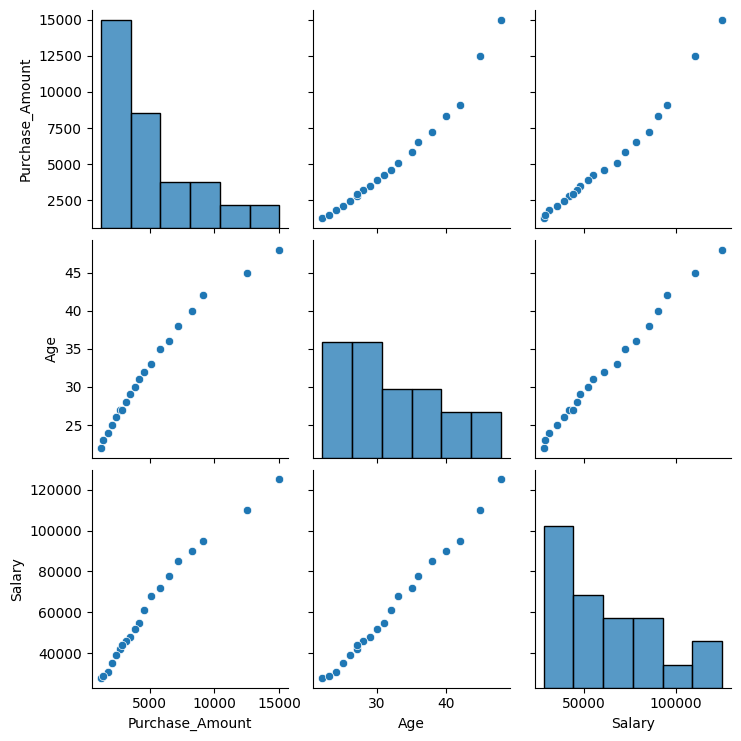


--- Q36: Automated Insights ---
Features strongly associated with Purchase_Amount (|r| > 0.5): ['Age', 'Salary', 'Experience', 'Rating', 'high_purchase']

--- Q37: Target Imbalance Check ---
Gender
Female    0.555556
Male      0.444444
Name: proportion, dtype: float64


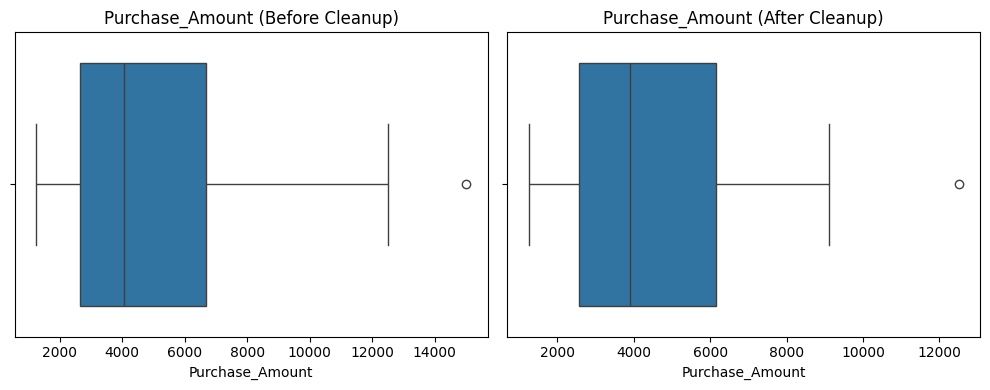


--- Q39: Summary Report ---


,Mean,Skewness,Outliers Count
ID,10.50,0.000000,0
Age,32.05,0.673258,0
Salary,61650.00,0.783030,0
Purchase_Amount,5177.50,1.383910,1
Experience,8.30,0.921405,0
Rating,4.34,-0.058777,0



--- Q40: Reusable full EDA function is loaded. ---


In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def detect_outliers_iqr(data_col):
    q1 = data_col.quantile(0.25)
    q3 = data_col.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return (data_col < lower) | (data_col > upper)

print("--- Q31: Outlier Detection Function defined. ---")

clean_df = df[~detect_outliers_iqr(df["Purchase_Amount"])].copy()
print("\n--- Q32: Outliers removed from 'Purchase_Amount' ---")
print(f"Original shape: {df.shape}, Cleaned shape: {clean_df.shape}")

numeric_cols = df.select_dtypes(include=np.number).columns.drop("high_purchase", errors="ignore")
scaler_minmax = MinMaxScaler()
df_normalized = df.copy()
df_normalized[numeric_cols] = scaler_minmax.fit_transform(df[numeric_cols].fillna(df[numeric_cols].mean()))
print("\n--- Q33: Normalized Features (Min-Max) ---")
display(df_normalized[numeric_cols].head())

scaler_std = StandardScaler()
df_standardized = df.copy()
df_standardized[numeric_cols] = scaler_std.fit_transform(df[numeric_cols].fillna(df[numeric_cols].mean()))
print("\n--- Q34: Standardized Features (Z-score) ---")
display(df_standardized[numeric_cols].head())

print("\n--- Q35: Pairplot ---")
sns.pairplot(df[["Purchase_Amount", "Age", "Salary"]].dropna())
plt.show()

print("\n--- Q36: Automated Insights ---")
corr_target = df.corr(numeric_only=True)["Purchase_Amount"]
features_above_05 = corr_target[abs(corr_target) > 0.5].index.tolist()
features_above_05.remove("Purchase_Amount")
print(f"Features strongly associated with Purchase_Amount (|r| > 0.5): {features_above_05}")

print("\n--- Q37: Target Imbalance Check ---")
if "Gender" in df.columns:
    print(df["Gender"].value_counts(normalize=True))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.boxplot(x=df["Purchase_Amount"])
plt.title("Purchase_Amount (Before Cleanup)")
plt.subplot(1, 2, 2)
sns.boxplot(x=clean_df["Purchase_Amount"])
plt.title("Purchase_Amount (After Cleanup)")
plt.tight_layout()
plt.show()

print("\n--- Q39: Summary Report ---")
summary_report = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Skewness": df[numeric_cols].skew(),
    "Outliers Count": [detect_outliers_iqr(df[col].dropna()).sum() for col in numeric_cols]
})
display(summary_report)

def run_full_eda(input_df):
    print("=== FULL AUTOMATED EDA REPORT ===")
    print("\n1. Dataset Dimensions:", input_df.shape)
    print("\n2. Missing values per column:\n", input_df.isnull().sum())
    print("\n3. Basic Statistics:\n")
    display(input_df.describe())
    print("\n4. Plotting Heatmap...")
    plt.figure(figsize=(6, 4))
    sns.heatmap(input_df.corr(numeric_only=True), annot=True, cmap="coolwarm")
    plt.title("Correlation Matrix")
    plt.show()

print("\n--- Q40: Reusable full EDA function is loaded. ---")